In [1]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 716.2/716.2 kB 6.1 MB/s eta 0:00:00


In [97]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [98]:
from ultralytics import YOLO

# Load a model
model = YOLO('yolov8n-pose.pt')  # load an official model
#model = YOLO('path/to/best.pt')  # load a custom model

# Define path to video file
#source = '/content/drive/MyDrive/0_497Project/preliminarydata/ZOOM0007.mov'
#source = ' /content/drive/MyDrive/0_497Project/preliminarydata/splittingzoom9/output_video_7.avi'
source='/content/drive/MyDrive/0_497Project/preliminarydata/results/Testinggesturesheadpose/output_video_7.avi'
# Run inference on the source
results = model(source, stream=True)  # generator of Results objects

In [99]:

# Below VideoWriter object will create
# a frame of above defined The output
# is stored in 'filename.avi' file.
import numpy as np
import cv2
from PIL import Image
#number of frames
i=0

result_dict={}
result_dict_n={}
for result in results:

  nb_of_people=result.keypoints.xy.shape[0]
  if nb_of_people>0:
    #if one person
    result_dict[i]={}
    result_dict_n[i]={}
    for j in range(nb_of_people):
      result_dict[i][j]=result.keypoints.xy.cpu().numpy()[j]
      result_dict_n[i][j]=result.keypoints.xyn.cpu().numpy()[j]

  im_array = result.plot()
  im = Image.fromarray(im_array[..., ::-1])  # RGB PIL image
  if i==0:
    video_output = cv2.VideoWriter(' /content/drive/MyDrive/0_497Project/preliminarydata/splittingzoom9/output_video_7_withpose_3.avi', cv2.VideoWriter_fourcc(*'MJPG'),30, im.size)
    #video_output = cv2.VideoWriter(, cv2.VideoWriter_fourcc(*'MJPG'),30, im.size)
  video_output.write(cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR))
  #im.save(str(i)+'results.jpg')  # save image
  i+=1


video 1/1 (1/841) /content/drive/MyDrive/0_497Project/preliminarydata/results/Testinggesturesheadpose/output_video_7.avi: 384x640 (no detections), 167.3ms
video 1/1 (2/841) /content/drive/MyDrive/0_497Project/preliminarydata/results/Testinggesturesheadpose/output_video_7.avi: 384x640 (no detections), 150.7ms
video 1/1 (3/841) /content/drive/MyDrive/0_497Project/preliminarydata/results/Testinggesturesheadpose/output_video_7.avi: 384x640 (no detections), 136.8ms
video 1/1 (4/841) /content/drive/MyDrive/0_497Project/preliminarydata/results/Testinggesturesheadpose/output_video_7.avi: 384x640 (no detections), 147.1ms
video 1/1 (5/841) /content/drive/MyDrive/0_497Project/preliminarydata/results/Testinggesturesheadpose/output_video_7.avi: 384x640 (no detections), 133.5ms
video 1/1 (6/841) /content/drive/MyDrive/0_497Project/preliminarydata/results/Testinggesturesheadpose/output_video_7.avi: 384x640 (no detections), 139.0ms
video 1/1 (7/841) /content/drive/MyDrive/0_497Project/preliminarydata

In [63]:
result.keypoints.data.shape #px1, py1 of keypoint and pvisibility for each keypoint.

torch.Size([1, 17, 3])

In [9]:
print(i)

1280


#After collecting the keypoints for all frames and subjects

#I-Gesture has to be for each person

##A-To check for arm gesture, check the relative x and y position of 10 relative to 8 and 8 relative to 6. Likewise for left side, check for 9 relative to 7 and 7 relative to 5

In [66]:
#result_dict #113 and 117 have an extra subject in each

In [84]:
left_elbow=[] #7
left_wrist=[] #9
left_shoulder=[] #5
right_elbow=[] #8
right_wrist=[] #10
right_shoulder=[] #6
#Getting y values of each
for i in range (415):
  if result_dict[i][0].shape[0]!=0:
    left_elbow.append(result_dict[i][0][7][1])
    left_wrist.append(result_dict[i][0][9][1])
    left_shoulder.append(result_dict[i][0][5][1])
    right_elbow.append(result_dict[i][0][8][1])
    right_wrist.append(result_dict[i][0][10][1]) #10
    right_shoulder.append(result_dict[i][0][6][1]) #6

In [83]:
result_dict[408][0][5][1]

364.434

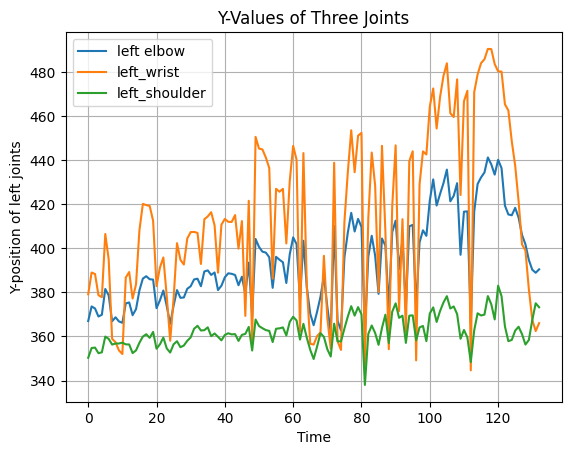

In [86]:
import numpy as np
import matplotlib.pyplot as plt
time = np.arange(len(left_elbow))
plt.plot(time, left_elbow, label='left elbow')
plt.plot(time, left_wrist, label='left_wrist')
plt.plot(time, left_shoulder, label='left_shoulder')
plt.xlabel('Time')
plt.ylabel('Y-position of left joints')
plt.title('Y-Values of Three Joints')
plt.legend()
plt.grid(True)
plt.show()


#II-Headpose

##A-Plot the ear versus eye for someone with head pose change versus without

Keypoints: 1, 2, 3, 4 ( do I assume disconnection in tracking as turn movement?)

In [100]:
left_ear=[] #3
left_eye=[] #1
nose=[] #0
right_ear=[] #4
right_eye=[] #2
#Get x values
for i in range (415):
  if result_dict_n[i][0].shape[0]!=0:
    left_ear.append(result_dict_n[i][0][3][0])
    left_eye.append(result_dict_n[i][0][1][0])
    nose.append(result_dict_n[i][0][0][0])
    right_ear.append(result_dict_n[i][0][4][0])
    right_eye.append(result_dict_n[i][0][2][0]) #10


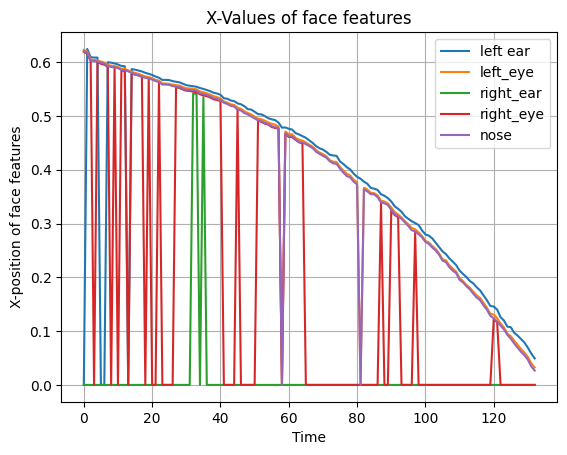

In [101]:
import numpy as np
import matplotlib.pyplot as plt
time = np.arange(len(left_elbow))
plt.plot(time, left_ear, label='left ear')
plt.plot(time, left_eye, label='left_eye')
plt.plot(time, right_ear, label='right_ear')
plt.plot(time, right_eye, label='right_eye')
plt.plot(time, nose, label='nose')

plt.xlabel('Time')
plt.ylabel('X-position of face features')
plt.title('X-Values of face features')
plt.legend()
plt.grid(True)
plt.show()